# Checkpoint 5 — Machine Learning & Modelling
## Agrupamento de vinhos com K-means

| Integrante | RM |
|---|---|
| Caio Ryan Velten Alves | 572913 |
| Carlos Alberto Oliveira Nascimento | 565694 |
| Davi França Aranda | 572751 |
| João Vitor Fernandes Gomes | 573882 |
| Murilo de Oliveira Moreira | 573534 |

### 1. Introdução — item a)
O problema é encontrar vinhos com perfis químicos semelhantes sem fornecer
seus cultivares ao algoritmo. A solução usa as 13 medições químicas, padronização
e K-means. Comparamos números de grupos pelo Elbow e pela silhueta e descrevemos
os grupos nas escalas originais para responder quais têm maior teor alcoólico
e maior concentração de ácido málico.

O arquivo `wine.csv` acompanha o projeto; a análise estatística das duas variáveis
está no notebook `CP5_Statistical_Computing_Wine.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
import sklearn

SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
df = pd.read_csv("wine.csv")
print(f"Dados: {df.shape[0]} vinhos, {df.shape[1]} colunas")
print(f"scikit-learn: {sklearn.__version__}; semente: {SEED}")
display(df.head())

Dados: 178 vinhos, 14 colunas
scikit-learn: 1.9.0; semente: 42


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### 2. Pré-processamento — item b)
`Wine` identifica o cultivar: incluí-la nas distâncias daria ao algoritmo a
resposta que ele deveria descobrir. Por isso, ela fica fora do ajuste e da escolha
de k. A comparação com cultivar aparece apenas no final, como diagnóstico.

Mantemos as 13 medições: são características químicas potencialmente relevantes.
Não removemos observações apenas por serem atípicas; não há evidência de erro
de medição. O K-means é sensível a extremos e a correlações, limitações retomadas
na conclusão. A imputação pela mediana só altera dados caso existam ausências.

Aplicamos `StandardScaler`: z = (x - média) / desvio-padrão. Assim, a escala
numérica de Proline não domina as distâncias em relação a Alcohol e Hue.

In [2]:
# Separa explicitamente os rótulos conhecidos das características de entrada.
y_cultivar = df["Wine"].copy()
X = df.drop(columns="Wine").copy()
assert X.shape[1] == 13 and all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
assert not np.isinf(X.to_numpy()).any(), "Há valores infinitos: revisar a origem."
assert not X.isna().all().any(), "Há coluna completamente vazia."
qualidade = pd.DataFrame({"Tipo": X.dtypes.astype(str), "Nulos": X.isna().sum()})
display(qualidade)
print("Linhas duplicadas:", df.duplicated().sum())

imputador = SimpleImputer(strategy="median")
X_imputado = imputador.fit_transform(X)
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X_imputado)
assert X_padronizado.shape == (len(df), 13)
assert np.isfinite(X_padronizado).all()
display(pd.DataFrame({"Média após padronizar": X_padronizado.mean(axis=0),
                      "Desvio após padronizar": X_padronizado.std(axis=0)}, index=X.columns))
# Neste arquivo não há nulos: a imputação não altera as observações.
# Não é uma tarefa de previsão de novos rótulos, mas uma análise exploratória
# do conjunto completo; não interpretamos os resultados como desempenho de teste.

,Tipo,Nulos
Alcohol,float64,0
Malic.acid,float64,0
Ash,float64,0
Acl,float64,0
Mg,int64,0
Phenols,float64,0
Flavanoids,float64,0
Nonflavanoid.phenols,float64,0
Proanth,float64,0
Color.int,float64,0


Linhas duplicadas: 0


,Média após padronizar,Desvio após padronizar
Alcohol,-8.382808e-16,1.0
Malic.acid,-1.197544e-16,1.0
Ash,-8.370333e-16,1.0
Acl,-3.991813e-17,1.0
Mg,-3.991813e-17,1.0
Phenols,0.000000e+00,1.0
Flavanoids,-3.991813e-16,1.0
Nonflavanoid.phenols,3.592632e-16,1.0
Proanth,-1.197544e-16,1.0
Color.int,2.494883e-17,1.0


### 3. Número de grupos: Elbow e Silhueta — item d)
No Elbow, observamos a inércia (soma das distâncias quadráticas até os centroides).
Ela sempre cai com k: procuramos uma mudança de inclinação, não o menor valor.
Na silhueta, cada vinho é comparado ao próprio grupo e ao grupo vizinho; valores
mais próximos de 1 indicam melhor separação. Avaliamos k de 2 a 10, sem usar `Wine`.

Cada ajuste usa `k-means++`, 30 inicializações e semente fixa para reduzir a
dependência de uma inicialização ruim. A regra operacional escolhe a maior
silhueta média dentro dessa faixa e confronta essa escolha com o Elbow.

,Inércia,Silhueta,Queda de inércia (%)
k,,,
1,2314.0000,NaN,NaN
2,1658.7589,0.2593,28.3164
3,1277.9285,0.2849,22.9588
4,1175.3519,0.2586,8.0268
5,1107.0073,0.2315,5.8148
6,1046.0023,0.2372,5.5108
7,981.5952,0.2036,6.1575
8,935.2012,0.1570,4.7264
9,889.8929,0.1499,4.8448


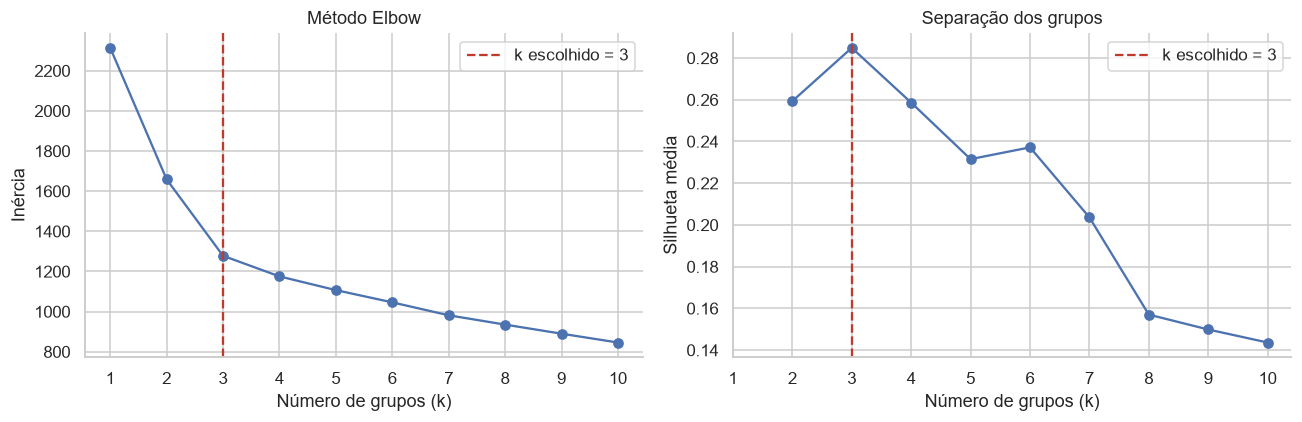

**Escolha pela silhueta:** k = 3, score = 0.2849. A escolha é relativa aos dados, à padronização e à faixa testada; não demonstra um número universal de tipos de vinho.

In [3]:
# Compara k sem usar os cultivares; várias inicializações reduzem mínimos locais.
modelos = {}
resultados = []
for k in range(1, 11):
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=30, random_state=SEED)
    rotulos = modelo.fit_predict(X_padronizado)
    modelos[k] = modelo
    resultados.append({"k": k, "Inércia": modelo.inertia_,
                       "Silhueta": silhouette_score(X_padronizado, rotulos) if k > 1 else np.nan})
metricas = pd.DataFrame(resultados).set_index("k")
metricas["Queda de inércia (%)"] = -metricas["Inércia"].pct_change() * 100
k_escolhido = int(metricas["Silhueta"].idxmax())
display(metricas.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metricas.index, metricas["Inércia"], marker="o")
axes[0].set(xlabel="Número de grupos (k)", ylabel="Inércia", title="Método Elbow")
axes[1].plot(metricas.index[1:], metricas["Silhueta"].iloc[1:], marker="o")
axes[1].set(xlabel="Número de grupos (k)", ylabel="Silhueta média", title="Separação dos grupos")
for ax in axes:
    ax.axvline(k_escolhido, color="#c0392b", ls="--", label=f"k escolhido = {k_escolhido}")
    ax.set_xticks(range(1, 11))
    ax.legend()
plt.tight_layout()
plt.show()
display(Markdown(f"**Escolha pela silhueta:** k = {k_escolhido}, score = "
                 f"{metricas.loc[k_escolhido, 'Silhueta']:.4f}. "
                 "A escolha é relativa aos dados, à padronização e à faixa testada; "
                 "não demonstra um número universal de tipos de vinho."))

### 4. Ajuste final do K-means — item c)
**Leitura do Elbow:** a inércia cai de 1658,76 (k=2) para 1277,93 (k=3),
redução de 22,96%. De k=3 para k=4, a queda passa a 8,03%, indicando
um cotovelo próximo de k=3. Isso converge com a maior silhueta média,
0,2849 em k=3, embora haja sobreposição entre os grupos.

Usamos o modelo do k selecionado. O K-means alterna a atribuição de cada ponto
ao centroide mais próximo e a atualização dos centroides até convergir.
Os números dos grupos são apenas identificadores, sem ordem de qualidade.

In [4]:
# Reutiliza o ajuste com maior silhueta média, selecionado na etapa anterior.
modelo_final = modelos[k_escolhido]
grupos = modelo_final.labels_ + 1  # identificação mais fácil de ler: começa em 1
resultado = pd.DataFrame(X_imputado, columns=X.columns, index=df.index)
resultado["Grupo"] = grupos
tamanhos = resultado.groupby("Grupo").size().rename("Quantidade").to_frame()
tamanhos["Percentual (%)"] = tamanhos["Quantidade"] / len(resultado) * 100
display(tamanhos.round(2))
print("Iterações até convergência:", modelo_final.n_iter_)
print("Silhueta média:", round(silhouette_score(X_padronizado, grupos), 4))
assert tamanhos["Quantidade"].sum() == len(df)

# Os centroides são médias no espaço padronizado; voltamos à escala original.
centroides = pd.DataFrame(scaler.inverse_transform(modelo_final.cluster_centers_),
                         columns=X.columns, index=range(1, k_escolhido + 1))
centroides.index.name = "Grupo"
assert np.allclose(centroides, resultado.groupby("Grupo")[X.columns].mean())
display(centroides.round(3))

,Quantidade,Percentual (%)
Grupo,,
1,65,36.52
2,51,28.65
3,62,34.83


Iterações até convergência: 7
Silhueta média: 0.2849


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Grupo,,,,,,,,,,,,,
1,12.251,1.897,2.231,20.063,92.738,2.248,2.050,0.358,1.624,2.973,1.063,2.803,510.169
2,13.134,3.307,2.418,21.241,98.667,1.684,0.819,0.452,1.146,7.235,0.692,1.697,619.059
3,13.677,1.998,2.466,17.463,107.968,2.848,3.003,0.292,1.922,5.454,1.065,3.163,1100.226


### 5. Perfis químicos e interpretação — item e)
Comparamos as médias, medianas e dispersões na escala original. `Malic.acid`
mede um componente da acidez: maior concentração de ácido málico não equivale
necessariamente a menor pH ou maior acidez total. A unidade desse atributo não
é informada no CSV; evitamos atribuir g/L sem confirmação da fonte.

No mapa de calor, valores positivos indicam centroides acima da média global,
em desvios-padrão. Isso permite comparar características com escalas diferentes.

Alcohol                              Malic.acid                      \
         mean  median    std    min    max       mean median    std   min   
Grupo                                                                       
1      12.251  12.250  0.533  11.03  13.86      1.897  1.610  1.012  0.74   
2      13.134  13.110  0.522  12.20  14.34      3.307  3.270  1.093  1.24   
3      13.677  13.735  0.559  11.56  14.83      1.998  1.765  0.676  1.35   

             ... Color.int                             Proline          \
        max  ...      mean median    std   min   max      mean  median   
Grupo        ...                                                         
1      5.80  ...     2.973    2.9  0.792  1.28   5.3   510.169   495.0   
2      5.65  ...     7.235    7.3  2.346  3.40  13.0   619.059   620.0   
3      4.04  ...     5.454    5.4  1.294  2.60   8.9  1100.226  1072.5   

                               
           std    min     max  
Grupo                          
1      142.732  278.0   886.0  
2      120.724  372.0   880.0  
3      232.722  465.0  1680.0  

[3 rows x 25 columns]

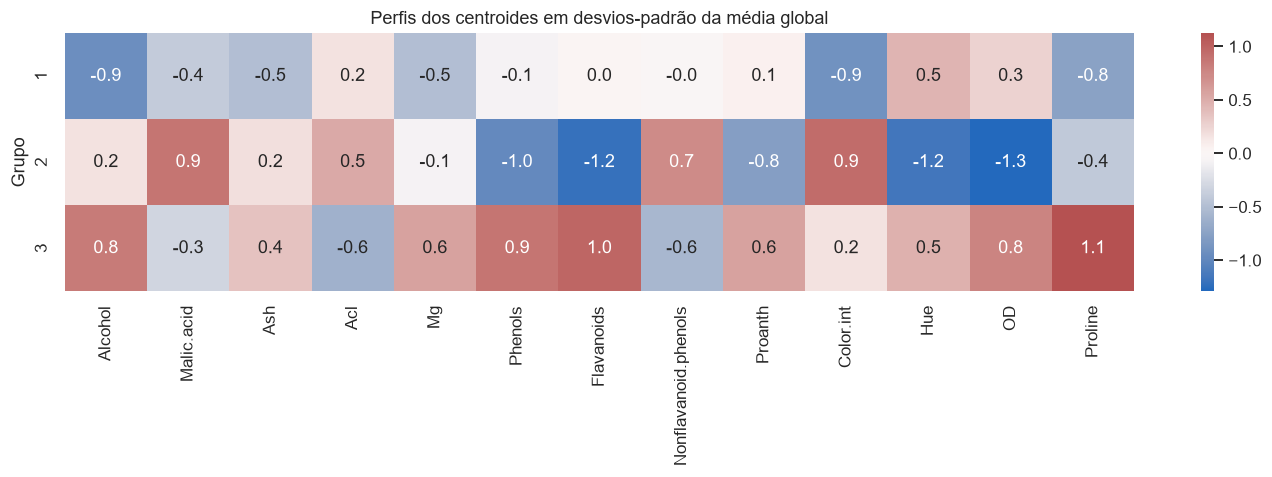

**Maior teor alcoólico médio:** grupo 3, 13.68% vol. **Maior concentração média de ácido málico:** grupo 2, 3.31 na escala do dataset.

- **Grupo 1 (65 vinhos):** álcool médio 12.25%; ácido málico médio 1.90. Maiores valores relativos: Acl (+0.17 DP), OD (+0.27 DP), Hue (+0.46 DP). Menores valores relativos: Alcohol (-0.93 DP), Color.int (-0.90 DP), Proline (-0.75 DP).

- **Grupo 2 (51 vinhos):** álcool médio 13.13%; ácido málico médio 3.31. Maiores valores relativos: Nonflavanoid.phenols (+0.73 DP), Malic.acid (+0.87 DP), Color.int (+0.94 DP). Menores valores relativos: OD (-1.29 DP), Flavanoids (-1.22 DP), Hue (-1.16 DP).

- **Grupo 3 (62 vinhos):** álcool médio 13.68%; ácido málico médio 2.00. Maiores valores relativos: Phenols (+0.89 DP), Flavanoids (+0.98 DP), Proline (+1.13 DP). Menores valores relativos: Acl (-0.61 DP), Nonflavanoid.phenols (-0.56 DP), Malic.acid (-0.30 DP).

In [5]:
# As estatísticas na escala original permitem interpretar álcool e ácido málico.
perfil = resultado.groupby("Grupo")[["Alcohol", "Malic.acid", "Ash", "Color.int", "Proline"]].agg(
    ["mean", "median", "std", "min", "max"])
display(perfil.round(3))
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pd.DataFrame(modelo_final.cluster_centers_, columns=X.columns,
                        index=centroides.index), cmap="vlag", center=0,
            annot=True, fmt=".1f", ax=ax)
ax.set(title="Perfis dos centroides em desvios-padrão da média global", ylabel="Grupo")
plt.tight_layout()
plt.show()

g_alcool = int(centroides["Alcohol"].idxmax())
g_acido = int(centroides["Malic.acid"].idxmax())
display(Markdown(f"**Maior teor alcoólico médio:** grupo {g_alcool}, "
                 f"{centroides.loc[g_alcool, 'Alcohol']:.2f}% vol. "
                 f"**Maior concentração média de ácido málico:** grupo {g_acido}, "
                 f"{centroides.loc[g_acido, 'Malic.acid']:.2f} na escala do dataset."))
for grupo in centroides.index:
    z = pd.Series(modelo_final.cluster_centers_[grupo - 1], index=X.columns).sort_values()
    alto = ", ".join(f"{v} ({z[v]:+.2f} DP)" for v in z.tail(3).index)
    baixo = ", ".join(f"{v} ({z[v]:+.2f} DP)" for v in z.head(3).index)
    display(Markdown(f"- **Grupo {grupo} ({tamanhos.loc[grupo, 'Quantidade']} vinhos):** "
                     f"álcool médio {centroides.loc[grupo, 'Alcohol']:.2f}%; "
                     f"ácido málico médio {centroides.loc[grupo, 'Malic.acid']:.2f}. "
                     f"Maiores valores relativos: {alto}. Menores valores relativos: {baixo}."))

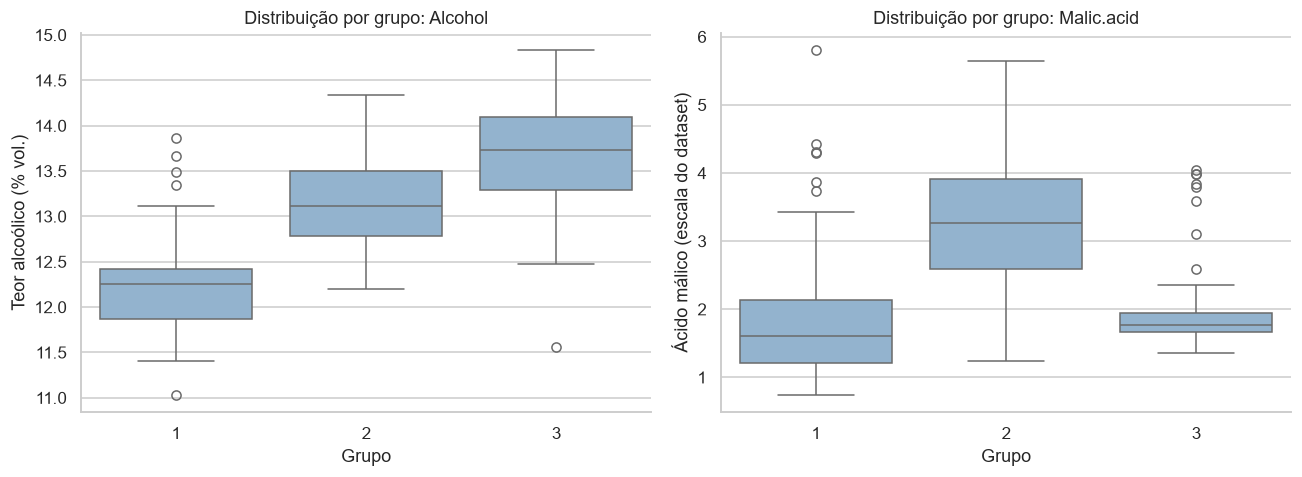

In [6]:
# Boxplots mostram a dispersão interna: uma média não representa todos os vinhos.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, var, nome in zip(axes, ["Alcohol", "Malic.acid"],
                        ["Teor alcoólico (% vol.)", "Ácido málico (escala do dataset)"]):
    sns.boxplot(data=resultado, x="Grupo", y=var, ax=ax, color="#89b4d8")
    ax.set(title=f"Distribuição por grupo: {var}", ylabel=nome)
plt.tight_layout()
plt.show()

### 6. Visualização dos grupos e qualidade interna
A PCA é aplicada **apenas para visualizar** os resultados em duas dimensões;
o K-means foi ajustado nas 13 características padronizadas. Projeções podem
ocultar separações existentes nas outras dimensões. A distribuição das silhuetas
revela vinhos próximos de fronteiras, inclusive possíveis valores negativos.

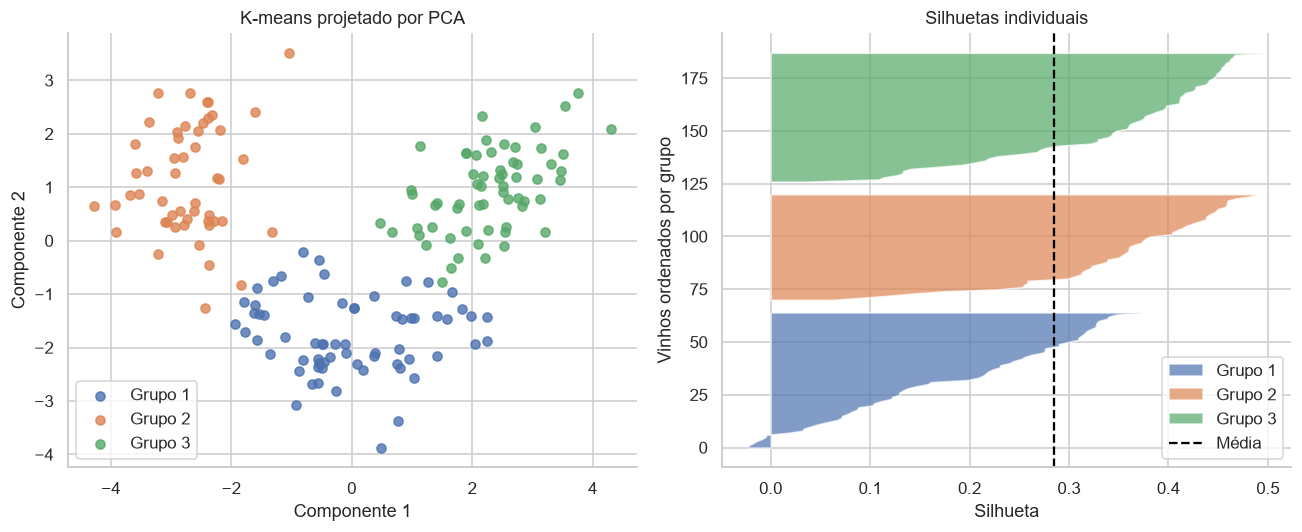

PCA: duas componentes retêm 55.4% da variância.
Vinhos com silhueta negativa: 7 de 178.


In [7]:
# PCA serve apenas ao gráfico: o K-means usou as 13 medições padronizadas.
pca = PCA(n_components=2)
projecao = pca.fit_transform(X_padronizado)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for grupo in centroides.index:
    mask = grupos == grupo
    axes[0].scatter(projecao[mask, 0], projecao[mask, 1], label=f"Grupo {grupo}", alpha=.8)
axes[0].set(title="K-means projetado por PCA", xlabel="Componente 1", ylabel="Componente 2")
axes[0].legend()
silhuetas = silhouette_samples(X_padronizado, grupos)
base = 0
for grupo in centroides.index:
    valores = np.sort(silhuetas[grupos == grupo])
    axes[1].fill_betweenx(np.arange(base, base + len(valores)), 0, valores, alpha=.7,
                          label=f"Grupo {grupo}")
    base += len(valores) + 5
axes[1].axvline(silhuetas.mean(), color="black", ls="--", label="Média")
axes[1].set(title="Silhuetas individuais", xlabel="Silhueta", ylabel="Vinhos ordenados por grupo")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"PCA: duas componentes retêm {pca.explained_variance_ratio_.sum():.1%} da variância.")
print(f"Vinhos com silhueta negativa: {(silhuetas < 0).sum()} de {len(df)}.")

### 7. Comparação externa opcional com os cultivares
Só agora usamos `Wine`. A tabela cruza os grupos descobertos e as classes
conhecidas; os números dos grupos não precisam coincidir com os cultivares.
O índice Rand ajustado (ARI) compara as duas partições sem depender dessa
numeração. Ele é um diagnóstico adicional, não foi usado para escolher k e
não deve ser interpretado como acurácia de um classificador.

In [8]:
# Comparação posterior: os cultivares não participaram do ajuste nem da escolha de k.
display(pd.crosstab(pd.Series(grupos, name="Grupo"), df["Wine"],
                    colnames=["Cultivar conhecido"]))
ari = adjusted_rand_score(y_cultivar, grupos)
print(f"ARI entre agrupamento e cultivares: {ari:.4f}")

Cultivar conhecido,1,2,3
Grupo,,,
1,0,65,0
2,0,3,48
3,59,3,0


ARI entre agrupamento e cultivares: 0.8975


### 8. Conclusão, limitações e próximos passos
**Resultado:** escolhemos três grupos com apoio do Elbow e da silhueta.
O grupo 1 reúne 65 vinhos, com álcool médio de 12,25% e ácido málico médio
de 1,90; o grupo 2 reúne 51 vinhos, com 13,13% e 3,31; o grupo 3 reúne
62 vinhos, com 13,68% e 2,00, respectivamente. Portanto, o grupo 3 tem
maior teor alcoólico médio, e o grupo 2 maior concentração média de ácido
málico. Sete vinhos apresentam silhueta negativa: a separação não é perfeita.
Os identificadores dos grupos referem-se a esta execução com semente 42.

Os grupos refletem semelhanças químicas, não categorias de qualidade ou preço.
Padronizar foi essencial para dar peso comparável às escalas das 13 medições.
Elbow e silhueta oferecem evidências complementares para k, sem impor os
três cultivares conhecidos como resposta.

**Limitações:** amostra pequena de 178 vinhos; K-means favorece grupos compactos
e distâncias euclidianas; extremos e variáveis correlacionadas influenciam os
centroides. Silhueta moderada e sobreposições indicam que há fronteiras ambíguas.
Os resultados descrevem este dataset e não comprovam generalização para
vinhos de outras regiões. Como extensão, seria possível avaliar estabilidade
por reamostragem e comparar outros métodos de agrupamento.

**Fontes:** enunciado Checkpoint 5; CSV distribuído no repositório do grupo,
originalmente disponibilizado em https://gist.github.com/tijptjik/9408623.
Documentação: https://scikit-learn.org/stable/modules/clustering.html#k-means
e https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html.